# Logistic Regression with scikit-learn


This notebook focuses on the **workflow** for implementing logistic regression with scikit-learn. You will see that the problem at hand can be solved perfectly with logistic regression. 

By the end of this notebook, you should know what steps to take in sequence to implement a model with scikit-learn and be able to apply it to unseen data.


## Data

To start with a simple example, let’s say that your goal is to build a logistic regression model in Python in order to determine whether candidates would get admitted to a prestigious university.

Here, there are two possible outcomes: Admitted (represented by the value of ‘1’) vs. Rejected (represented by the value of ‘0’).

You can then build a logistic regression in Python, where:

The dependent variable represents whether a person gets admitted and the 3 independent variables are the GMAT score, GPA and Years of work experience.

In [1]:
# Import libraries
import pandas as pd
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score

In [2]:
# Generating the data
candidates = {
    "gmat": [
        780, 750, 690, 710, 680, 730, 690, 720, 740, 690,
        610, 690, 710, 680, 770, 610, 580, 650, 540, 590,
        620, 600, 550, 550, 570, 670, 660, 580, 650, 660,
        640, 620, 660, 660, 680, 650, 670, 580, 590, 690,
    ],
    "gpa": [
        4, 3.9, 3.3, 3.7, 3.9, 3.7, 2.3, 3.3, 3.3, 1.7,
        2.7, 3.7, 3.7, 3.3, 3.3, 3, 2.7, 3.7, 2.7, 2.3,
        3.3, 2, 2.3, 2.7, 3, 3.3, 3.7, 2.3, 3.7, 3.3,
        3, 2.7, 4, 3.3, 3.3, 2.3, 2.7, 3.3, 1.7, 3.7,
    ],
    "work_experience": [
        3, 4, 3, 5, 4, 6, 1, 4, 5, 1,
        3, 5, 6, 4, 3, 1, 4, 6, 2, 3,
        2, 1, 4, 1, 2, 6, 4, 2, 6, 5,
        1, 2, 4, 6, 5, 1, 2, 1, 4, 5,
    ],
    "admitted": [
        1, 1, 1, 1, 1, 1, 0, 1, 1, 0,
        0, 1, 1, 1, 1, 0, 0, 1, 0, 0,
        0, 0, 0, 0, 0, 1, 1, 0, 1, 1,
        0, 0, 1, 1, 1, 0, 0, 0, 0, 1,
    ],
}

df = pd.DataFrame(
    candidates, columns=pd.Index(["gmat", "gpa", "work_experience", "admitted"])
)
df.head()

,gmat,gpa,work_experience,admitted
0,780,4.0,3,1
1,750,3.9,4,1
2,690,3.3,3,1
3,710,3.7,5,1
4,680,3.9,4,1


In [3]:
# Defining target and predictors
X = df[["gmat", "gpa", "work_experience"]]
y = df["admitted"]

In [4]:
# Train-test-split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=0
)

## Create Logistic Regression

In [5]:
# Modelling
lr = LogisticRegression()
lr.fit(X_train, y_train)
y_pred = lr.predict(X_test)

### Confusion Matrix

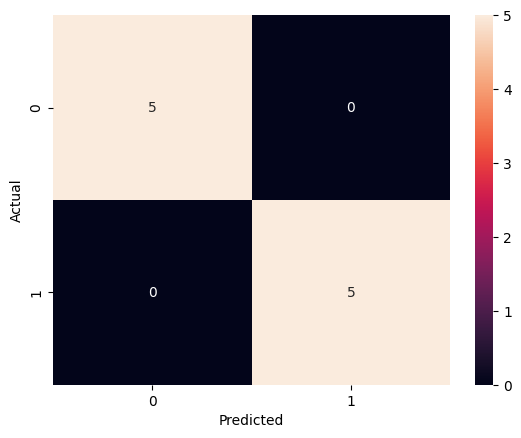

In [6]:
# Confusion matrix using pandas crosstab
conf_matrix = pd.crosstab(y_test, y_pred, rownames=["Actual"], colnames=["Predicted"])
sns.heatmap(conf_matrix, annot=True);

In [7]:
print("Accuracy: ", accuracy_score(y_test, y_pred))

Accuracy:  1.0


In [8]:
confusion_matrix(y_test, y_pred)

array([[5, 0],
       [0, 5]])

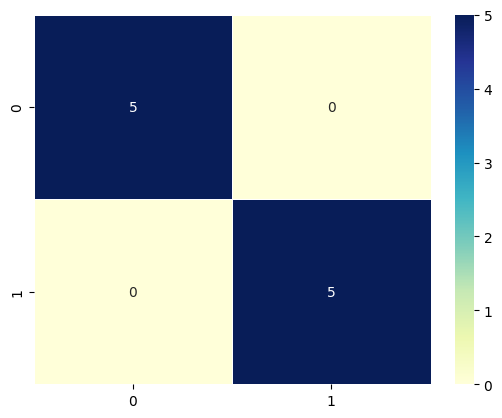

In [9]:
# Confusion matrix using the confusion_matrix function from sklearn
cfm = confusion_matrix(y_test, y_pred)
sns.heatmap(cfm, cmap="YlGnBu", annot=True, fmt="d", linewidths=0.5);

**Check your understanding**

- Check out the Scikit-Learn documentation for logistic regression and find out how to output the estimated parameters of your model.

<details>
<summary>Show answer</summary>

After fitting, the learned parameters live on the model object: `lr.coef_` holds the weight for each feature and `lr.intercept_` holds the bias term. These are the b1 and b0 of the logistic model. You can print them directly once the model is fit, for example `print(lr.coef_, lr.intercept_)`.
</details>

- Scikit-Learn usually has pretty good default values set for the hyperparameters of models. Try printing out all the defined hyperparameters of your model and check what these hyperparameters mean and what other options would be available for these hyperparameters.

<details>
<summary>Show answer</summary>

Call `lr.get_params()` to see every hyperparameter and its current value. The key ones for logistic regression are `C` (inverse of regularisation strength, where a smaller value means stronger regularisation), `l1_ratio` (the type of penalty: `0.0`, the default, is L2; `1.0` is L1; anything in between is elastic net), `penalty` (shown as `'deprecated'`: in older scikit-learn versions this chose `'l1'`, `'l2'` or `'elasticnet'`; since version 1.8 you use `l1_ratio` instead, and `C=np.inf` for no penalty at all), `solver` (the optimisation algorithm), and `max_iter` (how many iterations the solver may run). The scikit-learn documentation lists the allowed options for each.
</details>

- Try to change the threshold to 0.3 and print out the confusion matrix for this threshold. Before you run it, predict what will change — then check whether you were right.

<details><summary>
Click here for a hint for the last task
</summary>
You need to output the predicted probabilities of your model and use a function that gives you a value of 0 if the predicted probability is less than/equal to 0.3 and 1 if it is above the threshold. Now you can use this array as y_pred to print the confusion matrix.
</details>

<details>
<summary>Show answer</summary>

`predict()` always uses a fixed 0.5 cut-off, so to use a different threshold you work from the predicted probabilities instead. Get them with `lr.predict_proba(X_test)[:, 1]` (the probability of class 1), apply your own cut-off, then pass the result to `confusion_matrix`:

```python
proba = lr.predict_proba(X_test)[:, 1]
y_pred = (proba > 0.3).astype(int)
confusion_matrix(y_test, y_pred)
```

**On this dataset nothing changes** — the matrix is identical at 0.3 and 0.5 (5 true negatives, 5 true positives). Print `lr.predict_proba(X_test)[:, 1].round(3)` to see why: every test applicant's probability is either below 0.03 or above 0.93, so any threshold in between sorts them the same way. The classes are almost perfectly separable, so there is no trade-off to observe.

On data where the classes overlap, lowering the threshold labels more points as class 1, which raises recall (fewer false negatives) at the cost of more false positives, so precision falls. Try it on the Titanic data in the exercise notebook: in the lecture's split, moving from 0.5 to 0.3 raises recall from 0.73 to 0.81 while precision falls from 0.72 to 0.64.
</details>


---

# Addendum — regularising a logistic regression

The Bias-Variance lesson taught you to penalise a *regression* model's coefficients with
Ridge and Lasso, controlled by `alpha`. Classification has exactly the same problem and
exactly the same fix — but scikit-learn spells it differently, and the difference trips
people up.

**`LogisticRegression` is regularised by default.** Every model you have fitted in this
notebook already had an L2 penalty applied. The parameter that controls it is `C`, and it is
the **inverse** of the regularisation strength.

| | Ridge / Lasso | LogisticRegression |
|---|---|---|
| parameter | `alpha` | `C` |
| direction | **larger** `alpha` = **more** penalty | **larger** `C` = **less** penalty |
| relationship | — | `C ≈ 1 / alpha` |
| default | `alpha=1.0` | `C=1.0` |

So turning `C` *down* is what simplifies the model. Getting this backwards is one of the most
common errors in a first tuning attempt.

In [10]:
import numpy as np
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Scale first: the penalty acts on coefficient size, which depends on feature units.
# gmat runs in the hundreds, gpa is around 3 — without scaling the penalty is arbitrary.
print(X_train.std().round(3).to_dict())

{'gmat': 62.639, 'gpa': 0.671, 'work_experience': 1.745}


In [11]:
for C in [0.001, 0.01, 0.1, 1.0, 100.0]:
    model = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=1000))
    model.fit(X_train, y_train)
    coefs = model[-1].coef_[0]
    print(f"C={C:<8} train={model.score(X_train, y_train):.3f}  "
          f"test={model.score(X_test, y_test):.3f}  "
          f"coefficients={np.round(coefs, 3)}")

C=0.001    train=0.533  test=0.500  coefficients=[0.011 0.012 0.012]
C=0.01     train=0.967  test=0.900  coefficients=[0.095 0.108 0.102]
C=0.1      train=1.000  test=1.000  coefficients=[0.475 0.532 0.512]
C=1.0      train=1.000  test=1.000  coefficients=[1.183 1.305 1.246]
C=100.0    train=1.000  test=1.000  coefficients=[3.437 4.222 3.279]


Read the coefficient column down the page. At `C = 0.001` the penalty is overwhelming and
every coefficient is squeezed towards zero — the model has been regularised into predicting
almost the same thing for everyone. As `C` rises the coefficients grow and the model is
increasingly free to fit the training data.

This is the bias-variance dial again, in its classification form:

- **small `C`** → strong penalty → simple model → risk of **underfitting**
- **large `C`** → weak penalty → flexible model → risk of **overfitting**

## Choosing `C` honestly

Do not read `C` off the test set. Use cross-validation, exactly as you did for Ridge's
`alpha`.

In [12]:
from sklearn.model_selection import GridSearchCV

search = GridSearchCV(
    make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    param_grid={"logisticregression__C": np.logspace(-3, 3, 13)},
    cv=5,
    scoring="accuracy",
)
search.fit(X_train, y_train)

print(f"best C     : {search.best_params_['logisticregression__C']:.4f}")
print(f"cv accuracy: {search.best_score_:.4f}")
print(f"test accuracy: {search.score(X_test, y_test):.4f}")

best C     : 0.0316
cv accuracy: 1.0000
test accuracy: 1.0000


> **A note on this dataset.** There are only a few dozen applicants here and the classes are
> almost perfectly separable, so from `C = 0.1` upward both train and test accuracy sit at
> 1.000. You can see the **coefficients shrinking** clearly (0.011 at `C=0.001` up to 3.44 at
> `C=100`), but you cannot see the overfitting that large `C` risks — the data is too easy to
> produce it. For a case where the penalty visibly changes generalisation, look back at the
> Ridge and Lasso curves on the wine data in the Bias-Variance lesson.
>
> The exact best `C` here also moves a lot between splits. The procedure is the point, not
> the value.

> **Where this goes next.** The **Hyperparameter Tuning** lesson is entirely about the
> `GridSearchCV` call above — what it is doing, how to read `cv_results_`, and how to search
> more than one parameter at once. This lesson's lecture introduces
> `LogisticRegression`'s other important dial, `solver`, which solvers support which
> penalties, and elastic net via `l1_ratio`; the **Advanced ML-Pipelines** lesson uses them
> inside full pipelines.